In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm
from glob import glob
import pandas as pd
import pickle
import random
from PIL import Image
from glob import glob
import re
#from adjustText import adjust_text
import seaborn as sns
#import statannot
#from statannotations.Annotator import Annotator
import argparse
#import torch
import wandb
import sys
from functools import reduce
import torch
import math
import io
#import colorcet as cc
import scipy
#from adjustText import adjust_text
from sklearn.metrics import roc_auc_score, recall_score
from scipy.stats import ttest_rel


sys.path.append('../../MARS')
import MARS.run_lars.utils
from MARS.run_lars.dataset import get_datasets, dataset_center
from MARS.run_lars.utils import model_prediction, my_model, model_prediction_dual_mipview, my_model_feat_fusion

# 2D

In [7]:
df_single_mipview = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction/val/pred_val_mipview_aggregate.csv')
df_single_mipview = df_single_mipview[['filepath', 'PET_jco', 'PET_imwg', 'model_number', 'probs_mean', 'probs_max']]

df_dual_mipview = pd    .read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_dual_mipview_all_seeds_prediction/val/pred_val_mipview_aggregate.csv')
df_dual_mipview = df_dual_mipview[['filepath', 'PET_jco', 'PET_imwg', 'model_number', 'probs_mean', 'probs_max']]

df_3d = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/3D_all_seeds_prediction/val/pred_val_mipview_aggregate.csv')
df_3d = df_3d[['filepath', 'PET_jco', 'PET_imwg', 'model_number', 'probs_mean', 'probs_max']]


In [4]:
df_3d

,filepath,PET_jco,PET_imwg,model_number,probs_mean,probs_max
0,15476574,1.0,1.0,6,0.185106,0.185106
1,8749855,0.0,0.0,6,0.001021,0.001021
2,25763435,0.0,0.0,6,0.022123,0.022123
3,12807723,0.0,0.0,6,0.006618,0.006618
4,23389731,1.0,1.0,6,0.006170,0.006170
...,...,...,...,...,...,...
1475,8969288,0.0,0.0,3,0.074381,0.074381
1476,20023977,0.0,0.0,3,0.268651,0.268651
1477,40275445,1.0,1.0,3,0.727731,0.727731
1478,19394299,0.0,0.0,3,0.059014,0.059014


Model 0 mean AUC: 0.90
Model 0 max AUC: 0.91
Model 1 mean AUC: 0.87
Model 1 max AUC: 0.87
Model 2 mean AUC: 0.86
Model 2 max AUC: 0.86
Model 3 mean AUC: 0.87
Model 3 max AUC: 0.86
Model 4 mean AUC: 0.87
Model 4 max AUC: 0.87
Model 5 mean AUC: 0.87
Model 5 max AUC: 0.86
Model 6 mean AUC: 0.89
Model 6 max AUC: 0.89
Model 7 mean AUC: 0.88
Model 7 max AUC: 0.88
Model 8 mean AUC: 0.89
Model 8 max AUC: 0.88
Model 9 mean AUC: 0.86
Model 9 max AUC: 0.86
mean: {'roc_auc': 0.9035779260157671, 'sensitivity': 0.6078431372549019, 'specificity': 0.9587628865979382}
Max AUC
max: {'roc_auc': 0.9031736405902567, 'sensitivity': 0.7254901960784313, 'specificity': 0.9072164948453608}


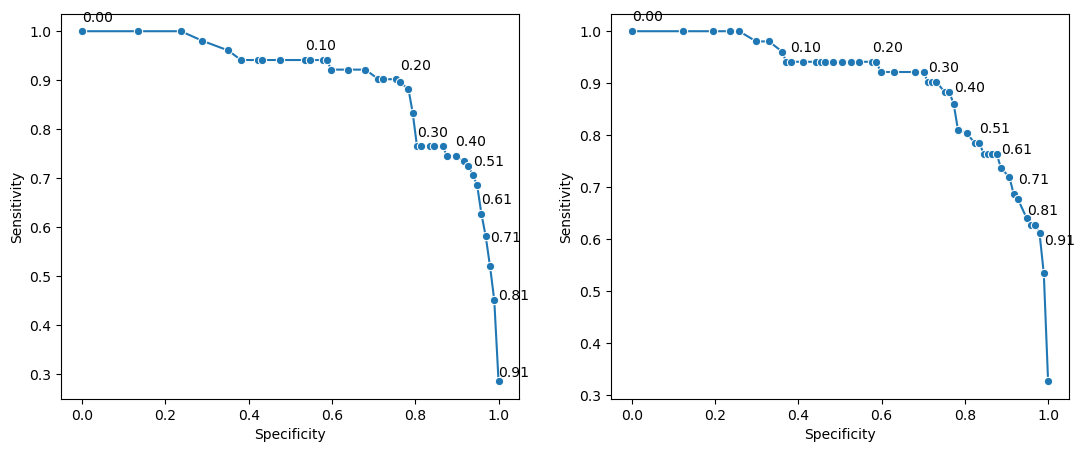

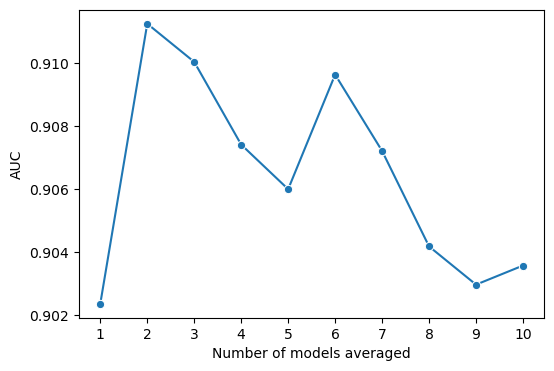

In [8]:
cutoff = 0.6623339340000001
def calc_metrics(this_df, pred_col):
    preds = this_df[pred_col]
    labels = this_df['PET_jco']

    metrics = {}
    metrics['roc_auc'] = roc_auc_score(labels, preds)
    metrics['sensitivity'] = recall_score(labels, preds > cutoff)
    metrics['specificity'] = recall_score(labels, preds > cutoff, pos_label=0)

    return metrics
def sensitivity_vs_specificity_plot(this_df, pred_col, ax=None):
    preds = this_df[pred_col]
    labels = this_df['PET_jco']

    sens_list = []
    spec_list = []
    text_list = []
    text_x_list = []
    text_y_list = []
    color_list = []
    for i, cutoff in enumerate(np.linspace(0, 1, 100)):
        sens = recall_score(labels, preds > cutoff)
        spec = recall_score(labels, preds > cutoff, pos_label=0)
        sens_list.append(sens)
        spec_list.append(spec)
        if i % 10 == 0:
            text_list.append(f'{cutoff:.2f}')
            text_x_list.append(spec)
            text_y_list.append(sens + .02)



    # plot 1-spec (x-axis) vs sensitivity (y-axis)
    # use seaborn with markers

    sns.lineplot(x=np.array(spec_list), y=sens_list, marker='o', errorbar=None, ax=ax)
    # put text by some points
    for x, y, text in zip(text_x_list, text_y_list, text_list):
        ax.text(x, y, text)
    ax.set_xlabel('Specificity')
    ax.set_ylabel('Sensitivity')

def auc_vs_num_models_plot(df, mean_aucs):
    rank = np.argsort(mean_aucs)[::-1]

    aucs_by_num_models = []
    for n_models in range(1, 11):
        selected_models = rank[:n_models]
        df_restricted = df[df['model_number'].isin(selected_models)].groupby('filepath').agg({'probs_mean': 'mean', 'PET_jco': 'first'}).reset_index()
        metrics = calc_metrics(df_restricted, 'probs_mean')
        aucs_by_num_models.append(metrics['roc_auc'])
    
    plt.figure(figsize=(6,4))
    sns.lineplot(x=np.arange(1, 11), y=aucs_by_num_models, marker='o', errorbar=None)
    plt.xlabel('Number of models averaged')
    plt.ylabel('AUC')
    plt.xticks(np.arange(1, 11))

def process_df(df):
    avged_df = df.groupby('filepath').agg({'probs_mean': 'mean', 'PET_jco': 'first'}).reset_index()
    maxed_df = df.groupby('filepath').agg({'probs_max': 'mean', 'PET_jco': 'first'}).reset_index()
    
    mean_aucs = []
    for model_num in range(10):
        this_df = df[df['model_number'] == model_num]
        print(f"Model {model_num} mean AUC: {calc_metrics(this_df, 'probs_mean')['roc_auc']:.2f}")
        print(f"Model {model_num} max AUC: {calc_metrics(this_df, 'probs_max')['roc_auc']:.2f}")
        mean_aucs.append(calc_metrics(this_df, 'probs_mean')['roc_auc'])
    
    # get indices of the greatest 5 mean AUCS
    top5_indices = np.argsort(mean_aucs)[-10:]
    #print(f'Top 5 models by mean AUC: {top5_indices}')

    avged_df_restricted = df[df['model_number'].isin(top5_indices)].groupby('filepath').agg({'probs_mean': 'mean', 'PET_jco': 'first'}).reset_index()
    #avged_df_restricted = avged_df

    metrics = calc_metrics(avged_df_restricted, 'probs_mean')
    print(f'mean: {metrics}')

    fig, ax = plt.subplots(1,2, figsize = (13,5))
    sensitivity_vs_specificity_plot(avged_df, 'probs_mean', ax=ax[0])
    sensitivity_vs_specificity_plot(maxed_df, 'probs_max', ax=ax[1])

    auc_vs_num_models_plot(df, mean_aucs)

    print('Max AUC')
    print(f"max: {calc_metrics(maxed_df, 'probs_max')}")

process_df(df_single_mipview)


Model 0 mean AUC: 0.90
Model 0 max AUC: 0.90
Model 1 mean AUC: 0.88
Model 1 max AUC: 0.88
Model 2 mean AUC: 0.88
Model 2 max AUC: 0.88
Model 3 mean AUC: 0.89
Model 3 max AUC: 0.89
Model 4 mean AUC: 0.89
Model 4 max AUC: 0.89
Model 5 mean AUC: 0.87
Model 5 max AUC: 0.87
Model 6 mean AUC: 0.89
Model 6 max AUC: 0.89
Model 7 mean AUC: 0.90
Model 7 max AUC: 0.90
Model 8 mean AUC: 0.88
Model 8 max AUC: 0.88
Model 9 mean AUC: 0.89
Model 9 max AUC: 0.89
mean: {'roc_auc': 0.9155043460683242, 'sensitivity': 0.6078431372549019, 'specificity': 0.9587628865979382}
Max AUC
max: {'roc_auc': 0.9155043460683242, 'sensitivity': 0.6078431372549019, 'specificity': 0.9587628865979382}


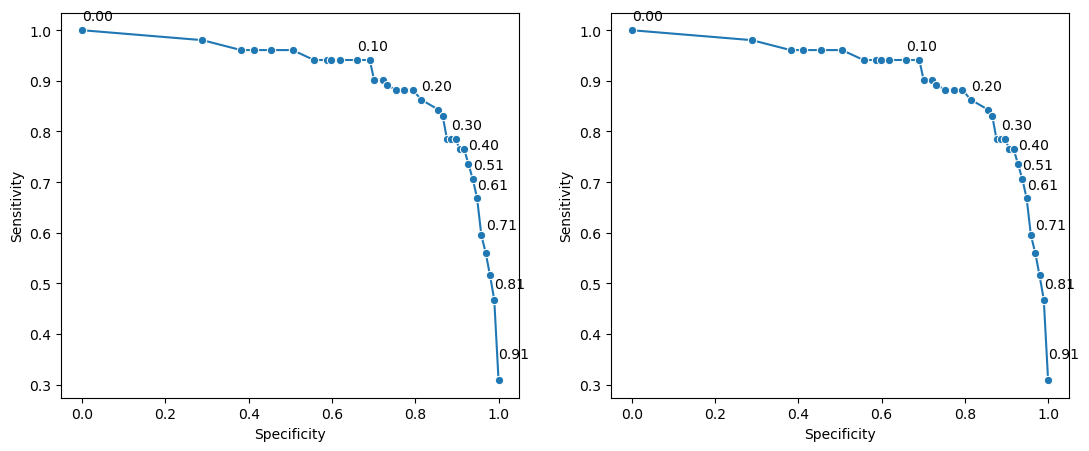

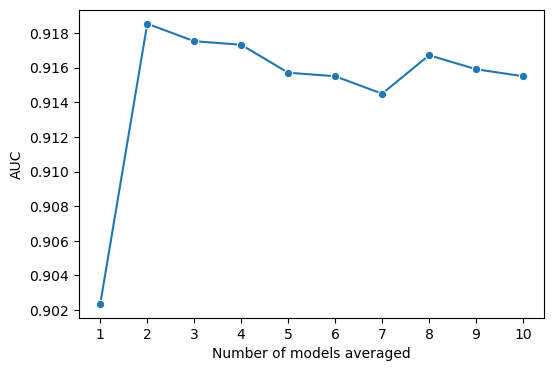

In [13]:
process_df(df_dual_mipview)

In [ ]:
# does single mipview have statistically significant difference in AUC compared to dual mipview?
def get_model_auc_list(this_df, prob_col):
    aucs = []
    for model_num in range(10):
        auc = calc_metrics(this_df[this_df['model_number'] == model_num], prob_col)['roc_auc']
        aucs.append(auc)
    return aucs

single_mean_aucs = get_model_auc_list(df_single_mipview, 'probs_mean')
dual_mean_aucs = get_model_auc_list(df_dual_mipview, 'probs_mean')

stat, p_value = ttest_rel(single_mean_aucs, dual_mean_aucs)
print(f"Paired t-test: stat={stat:.3f}, p-value={p_value:.3f}")

# again for max probabilities
single_max_aucs = get_model_auc_list(df_single_mipview, 'probs_max')
dual_max_aucs = get_model_auc_list(df_dual_mipview, 'probs_max')

# again for max probabilities

single_aucs = []
dual_aucs = []
for model_num in range(10):
    single_auc = calc_metrics(df_single_mipview[df_single_mipview['model_number'] == model_num], 'probs_max')['roc_auc']
    dual_auc = calc_metrics(df_dual_mipview[df_dual_mipview['model_number'] == model_num], 'probs_max')['roc_auc']
    single_aucs.append(single_auc)
    dual_aucs.append(dual_auc)

stat, p_value = ttest_rel(single_aucs, dual_aucs)
print(f"Paired t-test (max probs): stat={stat:.3f}, p-value={p_value:.3f}")

Paired t-test: stat=-2.403, p-value=0.040
Paired t-test (max probs): stat=-2.642, p-value=0.027


<Axes: xlabel='type', ylabel='auc'>

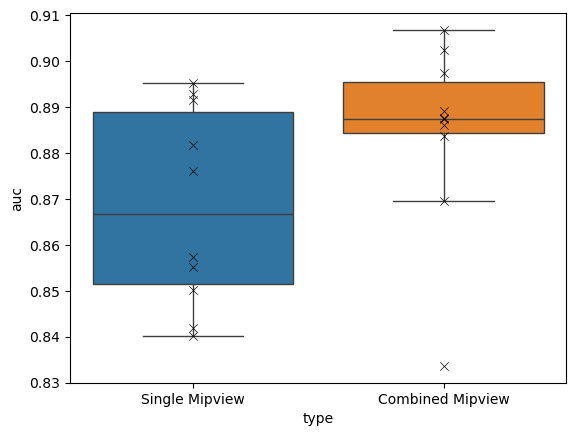

In [ ]:
# sns boxplot single_aucs and dual_aucs as groups
dicto = {'Single Mipview': single_aucs, 'Combined Mipview': dual_aucs, 'model_number': range(10)}
dfo = pd.DataFrame(dicto)
# move single_aucs and dual_aucs into a long format for seaborn
dfo_long = pd.melt(dfo, id_vars=['model_number'], value_vars=['Single Mipview', 'Combined Mipview'], var_name='type', value_name='auc')

# hide outliers
# also add markers
sns.boxplot(dfo_long, x='type', y='auc', hue='type', showfliers=False)

# markers should overly the boxplot
sns.scatterplot(dfo_long, x='type', y='auc', marker='x', color='black',zorder=5)

# add stat test using statannot




# FP Analysis for single mipview

In [14]:
fp_df = pd.read_excel('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/fps_table_reasons_4-28-26/MARS-FPs-final-with-model-probs-2D_bucketed_5-8-26.xlsx')

In [15]:
mapping = {
    'Infection / Inflammation': 'Infection/Inflammation',
    'Iatrogenic': 'Iatrogenic',
    'Physiologic': 'Physiologic',
    'Unknown': 'Unknown/Mixed',
    'Brown Fat': 'Brown Fat',
    'Other': 'Other'
}
fp_df['KN_reason'] = fp_df['KN_reason'].map(mapping)
fp_df['KN_reason'].value_counts()

KN_reason
Infection/Inflammation    56
Iatrogenic                29
Physiologic               22
Unknown/Mixed             15
Brown Fat                 10
Other                      6
Name: count, dtype: int64

Text(0.5, 1.0, 'False Positive Cases by Misclassification Category')

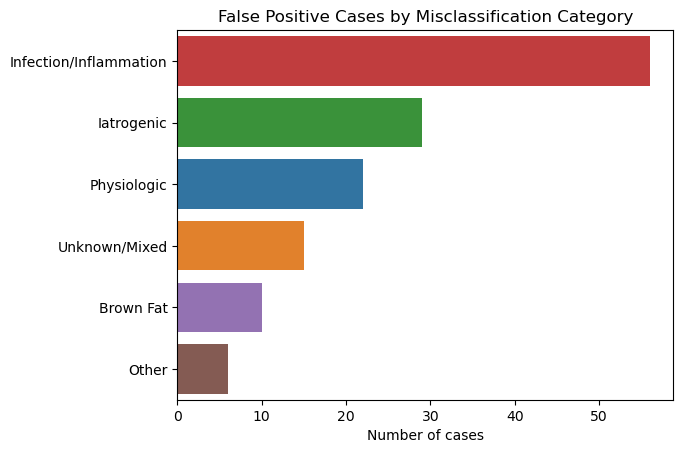

In [20]:
# bar graph from reasons using seaborn
# make the bar graph horizontal

sns.countplot(fp_df, y='KN_reason', order=fp_df['KN_reason'].value_counts().index, hue = 'KN_reason')
plt.ylabel('')
plt.xlabel('Number of cases')
plt.title('False Positive Cases by Misclassification Category')
# rotate y-axis tick labels
#plt.yticks(rotation=45, ha='right')

# Single Mipview prediction errors vs auxiliary labels

In [40]:
val_df = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction/val/pred_val_mipview_aggregate.csv')
# only take columns 0..64 in val_df
val_df = val_df.iloc[:, :64]
val_df = val_df[['filepath', 'PET_jco', 'model_number', 'probs_mean']]
# aggregate probs across model_number
val_df = val_df.groupby('filepath').agg({'probs_mean': 'mean', 'PET_jco': 'first'}).reset_index()
aux_val = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/aux_labels/val_df_with_auxiliary_labels.csv')

# join val_df with aux_val by filepath
aux_val.drop(columns=['PET_jco'], inplace=True)
val_df = val_df.merge(aux_val, on='filepath', how='left')

In [41]:
val_df

,filepath,probs_mean,PET_jco,filename,filename_header,fullfile,patient_age,patient_sex,patient_weight,smoking_status,...,tracer_dose,tracer_halflife,image_filter,contrast_route,axial_fov,PET_imwg,high_renal_uptake,high_bladder_uptake,injection_site_uptake,bowel_uptake
0,3602197,0.116255,0.0,3602197_pt_0.h5,3602197_pt_0.pkl,3602197/3602197_pt_0.h5,050Y,F,76.272000,NaN,...,553890014.6,6586.2,NaN,NaN,1556.0,0,1,1,0,0
1,5323200,0.122744,0.0,5323200_pt_0.h5,5323200_pt_0.pkl,5323200/5323200_pt_0.h5,070Y,M,73.548000,NO,...,495799987.8,6586.2,NaN,NaN,975.0,0,0,1,0,0
2,5340453,0.139494,0.0,5340453_pt_0.h5,5340453_pt_0.pkl,5340453/5340453_pt_0.h5,063Y,M,90.800000,NO,...,556109985.4,6586.2,NaN,NaN,975.0,0,0,1,0,0
3,5478993,0.002940,0.0,5478993_pt_0.h5,5478993_pt_0.pkl,5478993/5478993_pt_0.h5,048Y,M,83.990000,NO,...,549080017.1,6586.2,NaN,NaN,860.0,0,0,1,0,0
4,5509681,0.297680,0.0,5509681_pt_0.h5,5509681_pt_0.pkl,5509681/5509681_pt_0.h5,077Y,F,52.664000,NO,...,472490020.8,6586.2,NaN,NaN,745.0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
143,43026509,0.999999,1.0,43026509_pt_0.h5,43026509_pt_0.pkl,43026509/43026509_pt_0.h5,038Y,F,112.492000,UNKNOWN,...,440300000.0,6586.2,NaN,NaN,1815.0,1,1,1,0,0
144,43146522,0.006969,0.0,43146522_pt_0.h5,43146522_pt_0.pkl,43146522/43146522_pt_0.h5,077Y,F,65.318000,UNKNOWN,...,492100000.0,6586.2,NaN,NaN,1665.0,0,1,1,0,0
145,43188667,0.760283,0.0,43188667_pt_1.h5,43188667_pt_1.pkl,43188667/43188667_pt_1.h5,074Y,F,44.452058,UNKNOWN,...,547600000.0,6586.2,NaN,NaN,1500.0,0,1,1,0,0
146,43375061,0.091289,0.0,43375061_pt_1.h5,43375061_pt_1.pkl,43375061/43375061_pt_1.h5,064Y,F,74.389158,UNKNOWN,...,569800000.0,6586.2,NaN,NaN,1584.0,0,1,1,0,0


Mann Whitney U test for high_renal_uptake: stat=1959.000, p-value=0.208, n_group0=43, n_group1=105
Mann Whitney U test for high_bladder_uptake: stat=371.000, p-value=0.894, n_group0=5, n_group1=143
Mann Whitney U test for injection_site_uptake: stat=1954.000, p-value=0.017, n_group0=93, n_group1=55
Mann Whitney U test for bowel_uptake: stat=492.000, p-value=0.286, n_group0=139, n_group1=9


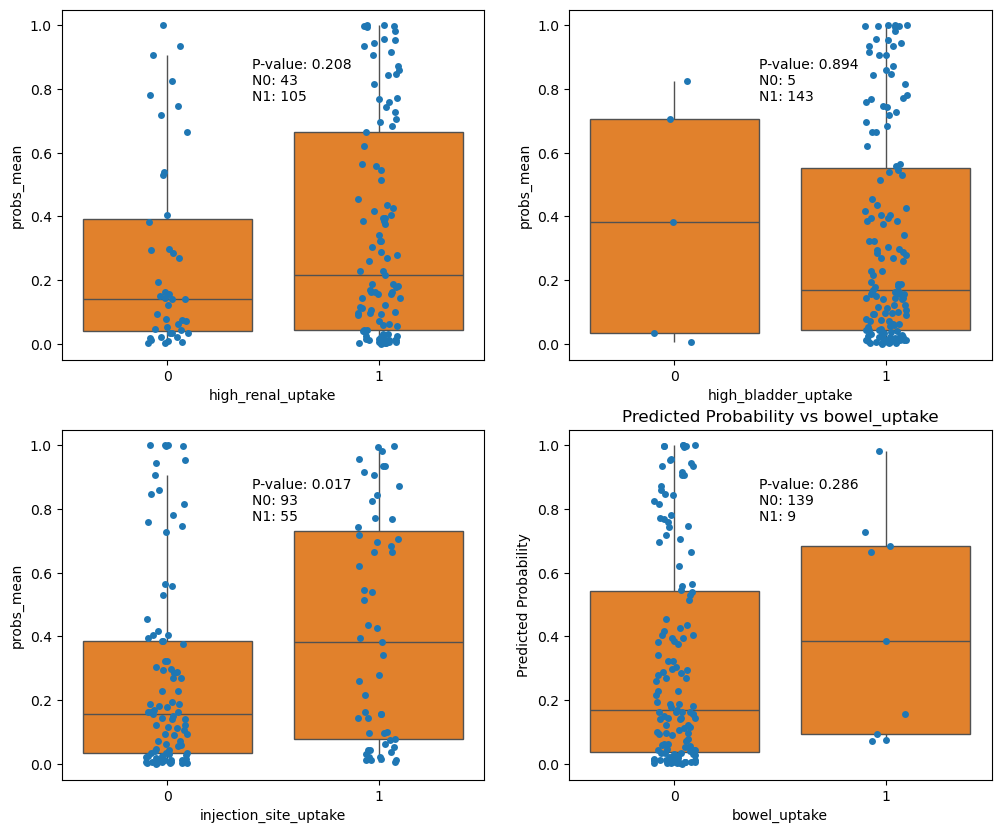

In [58]:
val_df[['high_renal_uptake', 'high_bladder_uptake', 'injection_site_uptake', 'bowel_uptake']]

# for each of the four variables, histogram plot the predicted probabilities
# arrange in 2x2 grid
fig, axs = plt.subplots(2, 2, figsize=(12, 10))
for i, var in enumerate(['high_renal_uptake', 'high_bladder_uptake', 'injection_site_uptake', 'bowel_uptake']):
    # use a strip plot, with the label on x axis and the predicted probability on y axis
    # also add a box
    sns.stripplot(x=var, y='probs_mean', data=val_df, ax = axs[i//2, i%2])
    sns.boxplot(x=var, y='probs_mean', data=val_df, showcaps=False, showfliers = False, ax = axs[i//2, i%2])
    plt.xlabel(var)
    plt.ylabel('Predicted Probability')
    plt.title(f'Predicted Probability vs {var}')

    # mann whitney u test between the two groups
    group0 = val_df[val_df[var] == 0]['probs_mean']
    group1 = val_df[val_df[var] == 1]['probs_mean']
    stat, p_value = scipy.stats.mannwhitneyu(group0, group1)
    # add text to plot with the stat and p-value and number in each group shorthanded
    axs[i//2, i%2].text(0.4, .9, f'P-value: {p_value:.3f}\nN0: {len(group0)}\nN1: {len(group1)}', verticalalignment='top')
    print(f'Mann Whitney U test for {var}: stat={stat:.3f}, p-value={p_value:.3f}, n_group0={len(group0)}, n_group1={len(group1)}')

In [60]:
# calculate fisher exact test for each variable and the ground-truth label PET_jco
for var in ['high_renal_uptake', 'high_bladder_uptake', 'injection_site_uptake', 'bowel_uptake']:
    contingency_table = pd.crosstab(val_df[var], val_df['PET_jco'])
    stat, p_value = scipy.stats.fisher_exact(contingency_table)
    print(f'Fisher exact test for {var} and PET_jco: stat={stat:.3f}, p-value={p_value:.3f}')
    # print odds ratio
    odds_ratio = contingency_table.iloc[0,0] * contingency_table.iloc[1,1] / (contingency_table.iloc[0,1] * contingency_table.iloc[1,0])
    print(f'Odds ratio: {odds_ratio:.3f}')

Fisher exact test for high_renal_uptake and PET_jco: stat=1.790, p-value=0.183
Odds ratio: 1.790
Fisher exact test for high_bladder_uptake and PET_jco: stat=0.782, p-value=1.000
Odds ratio: 0.782
Fisher exact test for injection_site_uptake and PET_jco: stat=1.892, p-value=0.077
Odds ratio: 1.892
Fisher exact test for bowel_uptake and PET_jco: stat=0.948, p-value=1.000
Odds ratio: 0.948


# LARS vs MARS Single-mipview comparison

In [21]:
lars_df = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction_using_LARS/test/pred_test_mipview_aggregate.csv')
mars_df = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction/test/pred_test_mipview_aggregate.csv')

lars_df = lars_df.iloc[:, :64]
lars_df = lars_df[['filepath', 'PET_jco', 'model_number', 'probs_mean']]
# aggregate probs across model_number
lars_df = lars_df.groupby('filepath').agg({'probs_mean': ['mean', 'std'], 'PET_jco': 'first'}).reset_index()
lars_df.columns = ['filepath', 'probs_mean', 'probs_std', 'PET_jco']
lars_df['pred'] = (lars_df['probs_mean'] >= 0.359923).astype(int)

mars_df = mars_df.iloc[:, :64]
mars_df = mars_df[['filepath', 'PET_jco', 'model_number', 'probs_mean']]
# aggregate probs across model_number
# aggregate both mean and STD across model_number
mars_df = mars_df.groupby('filepath').agg({'probs_mean': ['mean', 'std'], 'PET_jco': 'first'}).reset_index()
mars_df.columns = ['filepath', 'probs_mean', 'probs_std', 'PET_jco']
mars_df['pred'] = (mars_df['probs_mean'] >= 0.300).astype(int)
# flatten levels

# join mars and LARS predictions on filepath
lars_df.drop(columns=['PET_jco'], inplace=True)
merged_df = lars_df.merge(mars_df, on='filepath', suffixes=('_lars', '_mars'))

LARS AUC: 0.878, MARS AUC: 0.908


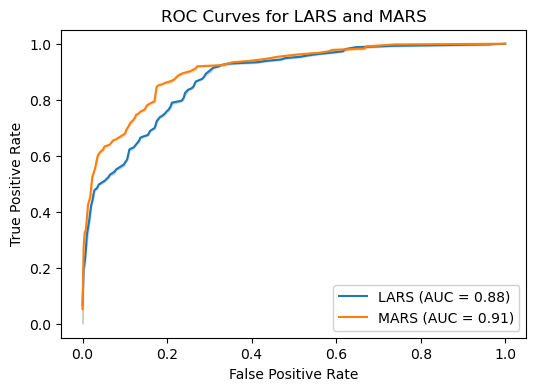

In [3]:
# print auc(pred_lars, pet_jco) and auc(pred_mars, pet_jco)
auc_lars = roc_auc_score(merged_df['PET_jco'], merged_df['probs_mean_lars'])
auc_mars = roc_auc_score(merged_df['PET_jco'], merged_df['probs_mean_mars'])
print(f'LARS AUC: {auc_lars:.3f}, MARS AUC: {auc_mars:.3f}')

# also show ROC curves for both models
from sklearn.metrics import roc_curve
fpr_lars, tpr_lars, _ = roc_curve(merged_df['PET_jco'], merged_df['probs_mean_lars'])
fpr_mars, tpr_mars, _ = roc_curve(merged_df['PET_jco'], merged_df['probs_mean_mars'])
plt.figure(figsize=(6,4))
sns.lineplot(x=fpr_lars, y=tpr_lars, label=f'LARS (AUC = {auc_lars:.2f})')
sns.lineplot(x=fpr_mars, y=tpr_mars, label=f'MARS (AUC = {auc_mars:.2f})')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for LARS and MARS')
plt.legend(loc='lower right', frameon=True, fancybox=True, framealpha=0.9)


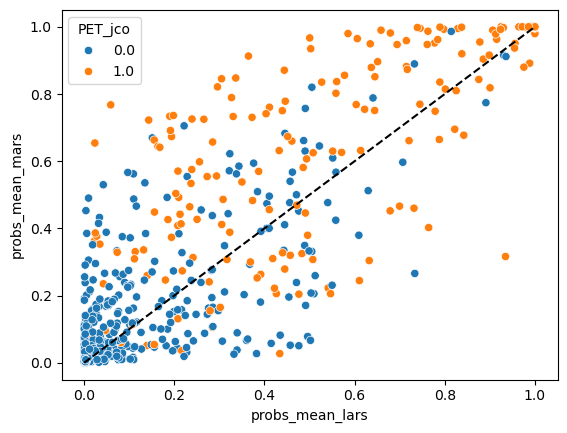

In [4]:
merged_df
# scatterplot probs_mean_lars vs probs_mean_mars
sns.scatterplot(x='probs_mean_lars', y='probs_mean_mars', hue='PET_jco', data=merged_df)
# plot the y=x line
plt.plot([0, 1], [0, 1], 'k--')

In [5]:
# compute a cohens kappa
from sklearn.metrics import cohen_kappa_score
cohen_kappa_score(merged_df['pred_lars'], merged_df['pred_mars'])

0.6031736359093735

Text(50.722222222222214, 0.5, 'LARS Prediction')

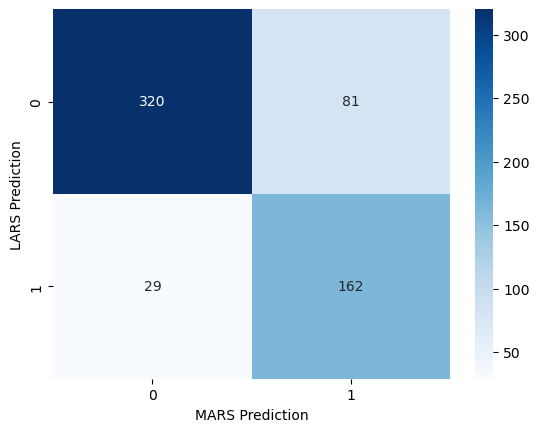

In [27]:
# plot confusion matrix between pred_lars and pred_mars
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(merged_df['pred_lars'], merged_df['pred_mars'], labels=[0, 1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=[0, 1], yticklabels=[0, 1])

# add labels
plt.xlabel('MARS Prediction')
plt.ylabel('LARS Prediction')


In [36]:
def write_df(df, pred_col, label_type, filename):
    tmp_df = pd.DataFrame({'accession': df['filepath'],
                            'label': df[pred_col],
                            'type': label_type,
                            'true_label': df['PET_jco']})
    tmp_df.to_csv(filename, index=False)

In [ ]:
# look at cases where LARS had high probability and MARS had low probability, i.e. minimize prob_MARS - prob_LARS
merged_df['delta'] = merged_df['probs_mean_mars'] - merged_df['probs_mean_lars']
# sort by delta
merged_df_sorted = merged_df.sort_values(by='delta')
# look at the 10 cases with the smallest delta and where pred_lars != pred_mars
merged_df_sorted = merged_df_sorted[merged_df_sorted['pred_lars'] != merged_df_sorted['pred_mars']]
# exclude cases where pred_mars doesn't match PET_jco 
merged_df_sorted = merged_df_sorted[merged_df_sorted['pred_mars'] == merged_df_sorted['PET_jco']]
# filter all decimals to 2 places
merged_df_sorted = merged_df_sorted.round(2)
print(merged_df_sorted.head(10))
write_df(merged_df_sorted.head(10), 'pred_lars', 'FP', '/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction_using_LARS/test/interpretability_comparing_LARS_MARS/FP_selected.csv')
write_df(merged_df_sorted.head(10), 'pred_mars', 'TN', '/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction/test/interpretability_comparing_LARS_MARS/TN_selected.csv')

# next, do same but for examples where LARS had low probability and MARS had high probability, i.e. maximize prob_MARS - prob_LARS
merged_df_sorted_desc = merged_df.sort_values(by='delta', ascending=False)
merged_df_sorted_desc = merged_df_sorted_desc[merged_df_sorted_desc['pred_lars'] != merged_df_sorted_desc['pred_mars']]
# exclude cases where pred_mars doesn't match PET_jco
merged_df_sorted_desc = merged_df_sorted_desc[merged_df_sorted_desc['pred_mars'] == merged_df_sorted_desc['PET_jco']]
merged_df_sorted_desc = merged_df_sorted_desc.round(2)
print(merged_df_sorted_desc.head(10))
write_df(merged_df_sorted_desc.head(10), 'pred_lars', 'FN', '/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction_using_LARS/test/interpretability_comparing_LARS_MARS/FN_selected.csv')
write_df(merged_df_sorted_desc.head(10), 'pred_mars', 'TP', '/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction/test/interpretability_comparing_LARS_MARS/TP_selected.csv')

     filepath  probs_mean_lars  probs_std_lars  pred_lars  probs_mean_mars  \
533  39870962             0.73            0.26          1             0.27   
409  25190041             0.50            0.08          1             0.07   
486  35817385             0.48            0.16          1             0.05   
273  18938720             0.50            0.31          1             0.08   
481  35538209             0.46            0.08          1             0.05   
295  19956067             0.41            0.29          1             0.06   
443  30028130             0.38            0.17          1             0.03   
384  24129932             0.43            0.30          1             0.08   
315  21375834             0.49            0.03          1             0.17   
365  23346553             0.55            0.10          1             0.23   

     probs_std_mars  PET_jco  pred_mars  delta  
533            0.16      0.0          0  -0.47  
409            0.12      0.0          0  -0

In [22]:
# make an NxN grid of some of these examples, pulling the images from the folder /gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_thumbnails_png_curated along with the filepath
thumb_dir = '/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_thumbnails_png_curated'
# make the grid actually N x 2
n = 5
grid_df = merged_df_sorted.head(n * 2).copy()

def resolve_thumbnail_path(filepath):
    filepath = str(filepath)
    candidates = []
    base = os.path.basename(filepath)
    stem = os.path.splitext(base)[0]
    candidates.extend([base, stem])
    digit_match = re.search(r'\d+', filepath)
    if digit_match is not None:
        candidates.append(digit_match.group(0))

    for candidate in candidates:
        matches = sorted(glob(os.path.join(thumb_dir, f'{candidate}_pt_*.png')))
        if len(matches) > 0:
            return matches[0]

    return None

fig, axs = plt.subplots(n, 2, figsize=(3.5 * 2, 4 * n))
axs = np.asarray(axs).reshape(n, 2)

for ax, (_, row) in zip(axs.flat, grid_df.iterrows()):
    img_path = resolve_thumbnail_path(row['filepath'])
    ax.axis('off')
    if img_path is None:
        ax.text(0.5, 0.5, 'Image not found', ha='center', va='center', fontsize=9)
        ax.set_title(str(row['filepath'].astype(int)), fontsize=7, wrap=True)
        continue

    img = Image.open(img_path)
    ax.imshow(img, cmap='gray')
    ax.set_title(str(row['filepath'].astype(int)) + f"\nLARS: {row['probs_mean_lars']:.2f}, MARS: {row['probs_mean_mars']:.2f}", fontsize=7, wrap=True)

for ax in axs.flat[len(grid_df):]:
    ax.axis('off')

plt.tight_layout()

NameError: name 'merged_df_sorted' is not defined

     filepath  probs_mean_lars  probs_std_lars  pred_lars  probs_mean_mars  \
538  40169610             0.06            0.08          0             0.77   
33    6225371             0.02            0.04          0             0.65   
527  39395365             0.14            0.18          0             0.72   
34    6270461             0.19            0.26          0             0.73   
539  40243357             0.30            0.21          0             0.85   
460  32882394             0.20            0.18          0             0.74   
429  27816680             0.30            0.33          0             0.82   
125  10342506             0.15            0.20          0             0.67   
243  17756290             0.34            0.25          0             0.85   
255  18102739             0.16            0.18          0             0.66   

     probs_std_mars  PET_jco  pred_mars  delta  
538            0.22      1.0          1   0.71  
33             0.13      1.0          1   0

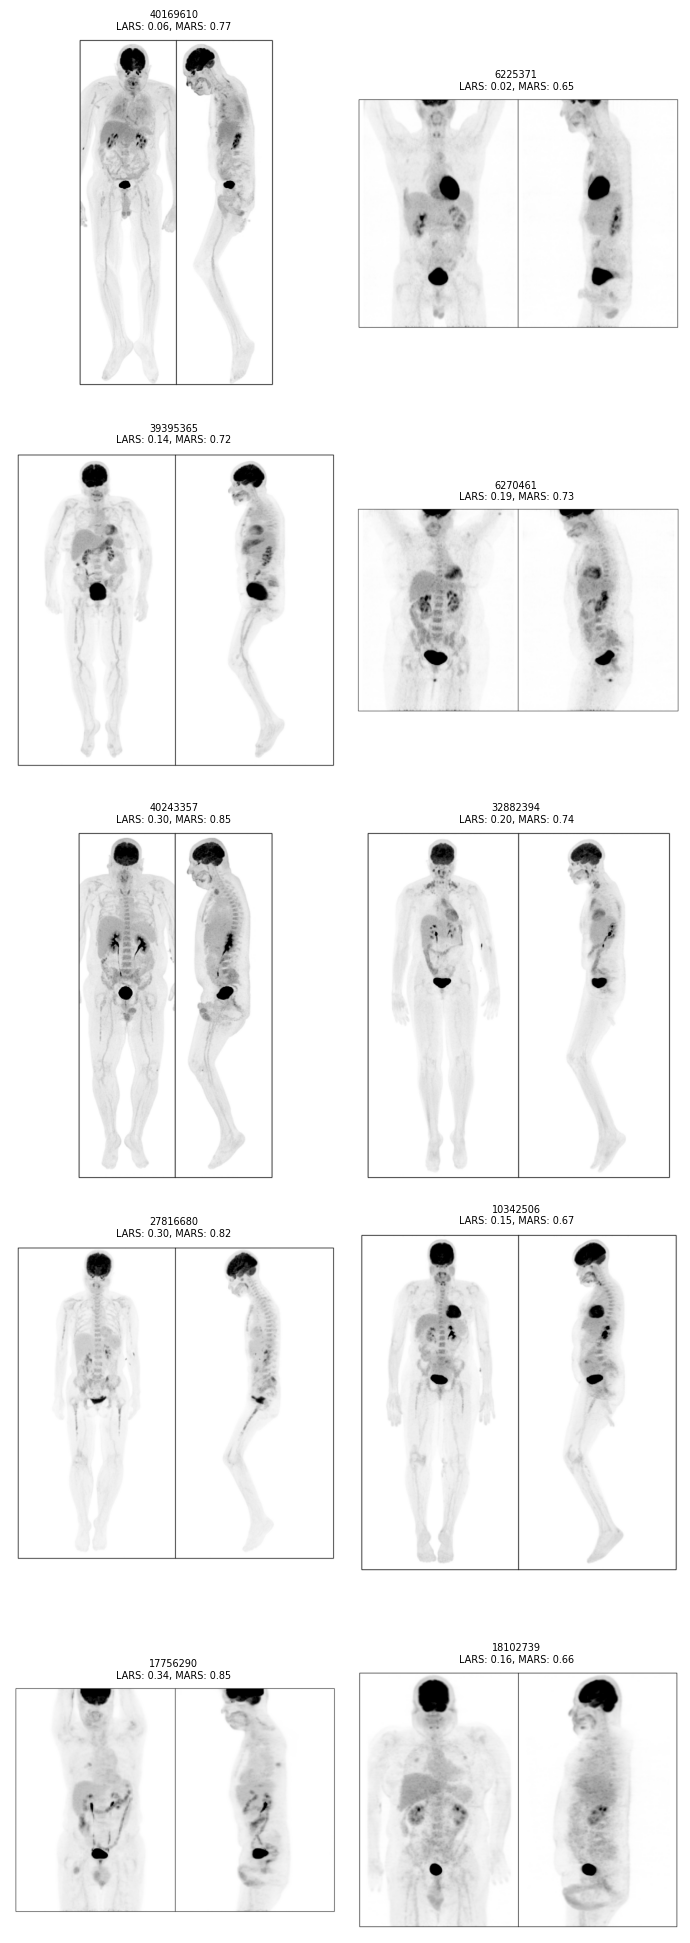

In [28]:
# next, do same but for examples where LARS had low probability and MARS had high probability, i.e. maximize prob_MARS - prob_LARS
merged_df_sorted_desc = merged_df.sort_values(by='delta', ascending=False)
merged_df_sorted_desc = merged_df_sorted_desc[merged_df_sorted_desc['pred_lars'] != merged_df_sorted_desc['pred_mars']]
merged_df_sorted_desc = merged_df_sorted_desc.round(2)
print(merged_df_sorted_desc.head(10))   
grid_df_desc = merged_df_sorted_desc.head(n * 2).copy()
fig, axs = plt.subplots(n, 2, figsize=(3.5 * 2, 4 * n))
axs = np.asarray(axs).reshape(n, 2)
for ax, (_, row) in zip(axs.flat, grid_df_desc.iterrows()):
    img_path = resolve_thumbnail_path(row['filepath'])
    ax.axis('off')
    if img_path is None:
        ax.text(0.5, 0.5, 'Image not found', ha='center', va='center', fontsize=9)
        ax.set_title(str(row['filepath'].astype(int)), fontsize=7, wrap=True)
        continue

    img = Image.open(img_path)
    ax.imshow(img, cmap='gray')
    ax.set_title(str(row['filepath'].astype(int)) + f"\nLARS: {row['probs_mean_lars']:.2f}, MARS: {row['probs_mean_mars']:.2f}", fontsize=7, wrap=True)
for ax in axs.flat[len(grid_df_desc):]:
    ax.axis('off')
plt.tight_layout()


In [24]:
f_lars = '/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction_using_LARS/test/interpretability_comparing_LARS_MARS/interpretability'
f_mars = '/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction/test/interpretability_comparing_LARS_MARS/interpretability'


L1 = glob(os.path.join(f_mars, '*', '*', 'GuidedGradCam_explain*'))
L2 = glob(os.path.join(f_lars, '*', '*', 'GuidedGradCam_explain1*'))
id1 = [x.split('/')[-2] for x in L1];
id2 = [x.split('/')[-2] for x in L2];
df1 = pd.DataFrame({'id': id1, 'path': L1})
df2 = pd.DataFrame({'id': id2, 'path': L2})
# merge df1 and df2 on id
merged_explain_df = df1.merge(df2, on='id', suffixes=('_mars', '_lars'))

In [ ]:
# for each id, create a plot with the png images at the specified paths as a 1x2 grid
for _, row in merged_explain_df.iterrows():
    img_mars = Image.open(row['path_mars'])
    img_lars = Image.open(row['path_lars'])
    fig, axs = plt.subplots(1, 2, figsize=(8, 4), dpi=600)
    axs[0].imshow(img_mars)
    axs[0].set_title('MARS')
    axs[0].axis('off')
    axs[1].imshow(img_lars)
    axs[1].set_title('LARS')
    axs[1].axis('off')
    #plt.suptitle(f"ID: {row['id']}")
    plt.tight_layout()

    # save as png to /gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction_using_LARS/test/interpretability_comparing_LARS_MARS/joined
    save_path = os.path.join('/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction_using_LARS/test/interpretability_comparing_LARS_MARS/joined', f"{row['id']}.png")
    plt.savefig(save_path, bbox_inches='tight', dpi=600)
    
    # save as a PNG to 

In [20]:
calc_metrics

<function __main__.calc_metrics(this_df, pred_col)>

In [ ]:
((merged_df['probs_mean_mars'] > 0.3) == merged_df['PET_jco']).mean()

np.float64(0.8327702702702703)

In [6]:
def calc_metrics(this_df, pred_col, cutoff):
    preds = this_df[pred_col]
    labels = this_df['PET_jco']

    metrics = {}
    metrics['accuracy'] = ((preds > cutoff) == labels).mean()
    metrics['roc_auc'] = roc_auc_score(labels, preds)
    metrics['sensitivity'] = recall_score(labels, preds > cutoff)
    metrics['specificity'] = recall_score(labels, preds > cutoff, pos_label=0)
    return metrics

# bootstrap AUC, accuracy, sensitivity, and specificity for both LARS and MARS, and compute 95% confidence intervals
def bootstrap_metrics(df, pred_col, n_bootstraps=1000, cutoff=0.5):
    rng = np.random.RandomState(42)
    bootstrapped_metrics = []
    for i in range(n_bootstraps):
        indices = rng.randint(0, len(df), len(df))
        sample_df = df.iloc[indices]
        metrics = calc_metrics(sample_df, pred_col, cutoff=cutoff)
        bootstrapped_metrics.append(metrics)
    return bootstrapped_metrics

lars_bootstrap = bootstrap_metrics(merged_df, 'probs_mean_lars', cutoff=0.359923)
mars_bootstrap = bootstrap_metrics(merged_df, 'probs_mean_mars', cutoff=0.300)

def compute_confidence_intervals(bootstrapped_metrics, metric_name):
    metric_values = [m[metric_name] for m in bootstrapped_metrics]
    lower = np.percentile(metric_values, 2.5)
    upper = np.percentile(metric_values, 97.5)
    return round(float(lower), 3), round(float(upper), 3)

for metric in ['accuracy', 'roc_auc', 'sensitivity', 'specificity']:
    lars_ci = compute_confidence_intervals(lars_bootstrap, metric)
    mars_ci = compute_confidence_intervals(mars_bootstrap, metric)
    print(f"{metric} - LARS 95% CI: {lars_ci}, MARS 95% CI: {mars_ci}")

# hypothesis test LARS vs MARS on roc_auc to see if there is a significant advantage to MARS over LARS
lars_aucs = [m['roc_auc'] for m in lars_bootstrap]
mars_aucs = [m['roc_auc'] for m in mars_bootstrap]
stat, p_value = ttest_rel(lars_aucs, mars_aucs, alternative = 'less')
print(f"Paired t-test for ROC AUC: stat={stat:.3f}, p-value={p_value:.3f}")

accuracy - LARS 95% CI: (0.758, 0.823), MARS 95% CI: (0.799, 0.861)
roc_auc - LARS 95% CI: (0.847, 0.905), MARS 95% CI: (0.883, 0.93)
sensitivity - LARS 95% CI: (0.599, 0.728), MARS 95% CI: (0.799, 0.901)
specificity - LARS 95% CI: (0.821, 0.896), MARS 95% CI: (0.781, 0.858)
Paired t-test for ROC AUC: stat=-78.974, p-value=0.000


# Ablation Analysis

### Dual Mipview


In [2]:
def auc_calc(df, label_col):
    # assumes df has columns label_col, filepath, and probs_mean. should already be subsetted for a model number
    auc = roc_auc_score(df[label_col], df['probs_mean'])
    return auc

In [4]:
def build_ablation_table(rt, label_col='PET_jco', n_models=10, total_train_n=None):
    aucs = []
    model_numbers = []
    fracs = []

    avg_aucs = []
    avg_fracs = []
    n_train_by_frac = {}

    for folder in sorted(os.listdir(rt)):
        folder_path = os.path.join(rt, folder)
        if not os.path.isdir(folder_path):
            continue

        parts = folder.split('_')
        if len(parts) < 2:
            continue

        try:
            frac = float(parts[1])
        except ValueError:
            continue

        path = os.path.join(rt, folder, 'pred_test_mipview_aggregate.csv')
        if not os.path.exists(path):
            print(f'Skipping {folder}: missing pred_test_mipview_aggregate.csv')
            continue

        df = pd.read_csv(path)
        df = df[['filepath', label_col, 'model_number', 'probs_mean']]

        if total_train_n is not None:
            n_train_by_frac[frac] = int(round(frac * total_train_n))
        else:
            # Fallback if training size is unknown.
            n_train_by_frac[frac] = np.nan

        available_models = sorted(df['model_number'].dropna().unique().astype(int))
        if n_models is not None:
            available_models = [m for m in available_models if m < n_models]

        # For each model, compute the AUC.
        for model_number in available_models:
            subset_df = df[df['model_number'] == model_number]
            auc = auc_calc(subset_df, label_col)

            fracs.append(frac)
            model_numbers.append(model_number)
            aucs.append(auc)

        # Also compute the AUC for the average of all models.
        avg_df = df.groupby('filepath').agg({'probs_mean': 'mean', label_col: 'first'}).reset_index()
        avg_auc = auc_calc(avg_df, label_col)
        avg_aucs.append(avg_auc)
        avg_fracs.append(frac)

    ablation_df = pd.DataFrame({'frac': fracs, 'model_number': model_numbers, 'auc': aucs})
    avg_df_plot = pd.DataFrame({'frac': avg_fracs, 'avg_auc': avg_aucs})
    return ablation_df, avg_df_plot, n_train_by_frac

def add_lars_zero_frac(ablation_df, avg_df_plot, n_train_by_frac, lars_root, label_col='PET_jco', n_models=10):
    if lars_root is None or not os.path.exists(lars_root):
        print(f'Skipping LARS zero-frac: path does not exist -> {lars_root}')
        return ablation_df, avg_df_plot, n_train_by_frac

    agg_path = os.path.join(lars_root, 'pred_test_mipview_aggregate.csv')
    if os.path.exists(agg_path):
        lars_df = pd.read_csv(agg_path)
        if {'filepath', label_col, 'model_number', 'probs_mean'}.issubset(lars_df.columns):
            lars_df = lars_df[['filepath', label_col, 'model_number', 'probs_mean']].copy()
        else:
            print('Skipping LARS zero-frac: aggregate file missing required columns')
            return ablation_df, avg_df_plot, n_train_by_frac
    else:
        pred_files = sorted(glob(os.path.join(lars_root, 'pred_test_*.csv')))
        if len(pred_files) == 0:
            print('Skipping LARS zero-frac: no pred_test_*.csv found')
            return ablation_df, avg_df_plot, n_train_by_frac

        per_model = []
        for i, path in enumerate(pred_files):
            df_i = pd.read_csv(path)
            if not {'filepath', label_col, 'probs'}.issubset(df_i.columns):
                print(f'Skipping LARS file (missing columns): {path}')
                continue
            df_i = df_i[['filepath', label_col, 'probs']].copy()
            df_i = df_i.rename(columns={'probs': 'probs_mean'})
            df_i['model_number'] = i
            per_model.append(df_i)

        if len(per_model) == 0:
            print('Skipping LARS zero-frac: no usable prediction files')
            return ablation_df, avg_df_plot, n_train_by_frac

        lars_df = pd.concat(per_model, ignore_index=True)

    available_models = sorted(lars_df['model_number'].dropna().unique().astype(int))
    if n_models is not None:
        available_models = [m for m in available_models if m < n_models]

    zero_rows = []
    for model_number in available_models:
        subset_df = lars_df[lars_df['model_number'] == model_number]
        auc = auc_calc(subset_df, label_col)
        zero_rows.append({'frac': 0.0, 'model_number': model_number, 'auc': auc})

    if len(zero_rows) > 0:
        zero_df = pd.DataFrame(zero_rows)
        ablation_df = pd.concat([ablation_df, zero_df], ignore_index=True)

    avg_df = lars_df.groupby('filepath').agg({'probs_mean': 'mean', label_col: 'first'}).reset_index()
    zero_avg_auc = auc_calc(avg_df, label_col)
    avg_df_plot = pd.concat([avg_df_plot, pd.DataFrame([{'frac': 0.0, 'avg_auc': zero_avg_auc}])], ignore_index=True)

    n_train_by_frac[0.0] = 0
    return ablation_df, avg_df_plot, n_train_by_frac

result_roots = {
    'Dual Mipview': {
        'root': '/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_dual_mipview_all_seeds_prediction/ablation_experiment/test',
        'train_csv': '/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/train_df.csv',
        'lars_zero_frac_root': None,
    },
    'Single Mipview': {
        'root': '/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction/ablation_fraction_seeds3/test',
        'train_csv': '/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/train_df.csv',
        'lars_zero_frac_root': '/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction_using_LARS/test',
    },
    'Single Mipview (Frozen Encoder)': {
        'root': '/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction/ablation_experiment3_freeze_encoder/test',
        'train_csv': '/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/train_df.csv',
        'lars_zero_frac_root': '/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction_using_LARS/test',
    }
}

ablation_results = {}
for name, cfg in result_roots.items():
    rt = cfg['root']
    train_csv = cfg.get('train_csv')

    if not os.path.exists(rt):
        print(f'Skipping {name}: path does not exist -> {rt}')
        continue

    total_train_n = None
    if train_csv is not None and os.path.exists(train_csv):
        total_train_n = len(pd.read_csv(train_csv))

    ablation_df, avg_df_plot, n_train_by_frac = build_ablation_table(
        rt,
        label_col='PET_jco',
        n_models=10,
        total_train_n=total_train_n,
    )

    lars_zero_frac_root = cfg.get('lars_zero_frac_root')
    if lars_zero_frac_root is not None:
        ablation_df, avg_df_plot, n_train_by_frac = add_lars_zero_frac(
            ablation_df,
            avg_df_plot,
            n_train_by_frac,
            lars_zero_frac_root,
            label_col='PET_jco',
            n_models=10,
        )

    ablation_results[name] = {
        'ablation_df': ablation_df,
        'avg_df_plot': avg_df_plot,
        'n_train_by_frac': n_train_by_frac,
        'total_train_n': total_train_n,
        'root': rt,
    }
    print(
        f"{name}: {len(ablation_df)} model-level rows, {len(avg_df_plot)} average points, "
        f"total_train_n={total_train_n}"
    )

Dual Mipview: 70 model-level rows, 7 average points, total_train_n=739
Single Mipview: 80 model-level rows, 8 average points, total_train_n=739
Single Mipview (Frozen Encoder): 80 model-level rows, 8 average points, total_train_n=739


/tmp/ipykernel_2289469/3285476853.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(tick_labels)


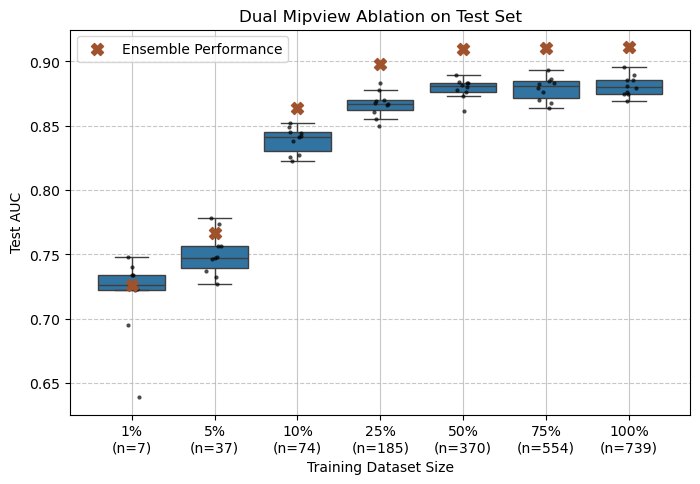

/tmp/ipykernel_2289469/3285476853.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(tick_labels)


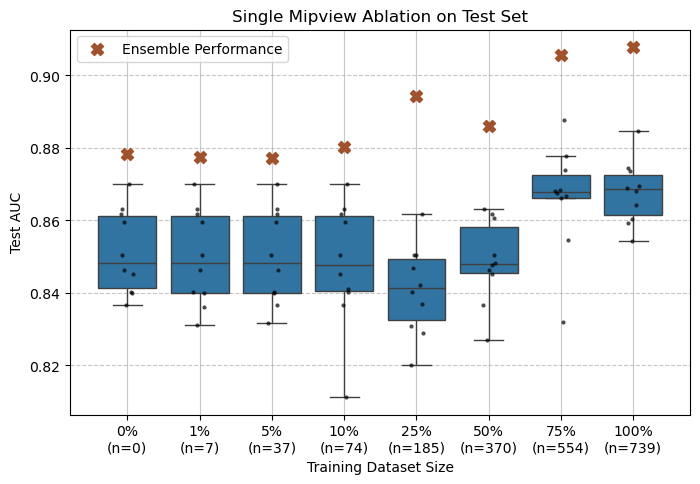

/tmp/ipykernel_2289469/3285476853.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(tick_labels)


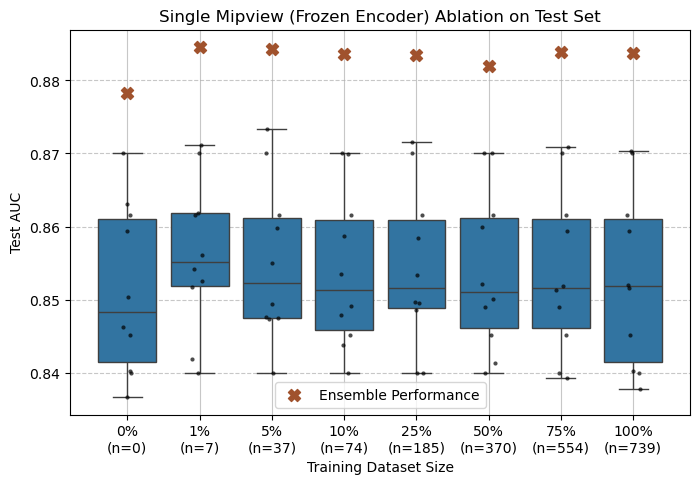

In [5]:
def plot_ablation_result(ablation_df, avg_df_plot, n_train_by_frac, title):
    frac_order = sorted(ablation_df['frac'].unique())
    if len(frac_order) == 0:
        print(f'No data to plot for {title}')
        return

    plot_df = ablation_df.copy()
    plot_df['frac'] = pd.Categorical(plot_df['frac'], categories=frac_order, ordered=True)

    fig, ax = plt.subplots(figsize=(8, 5))
    sns.boxplot(data=plot_df, x='frac', y='auc', order=frac_order, showfliers=False, ax=ax)
    sns.stripplot(data=plot_df, x='frac', y='auc', order=frac_order, color='black', jitter=0.1, size=3, alpha=0.7, ax=ax)

    # Map each frac value to the box index (0..N-1) and plot averages at those exact positions.
    x_pos_map = {f: i for i, f in enumerate(frac_order)}
    x_positions = [x_pos_map[float(f)] for f in avg_df_plot['frac']]
    ax.scatter(x_positions, avg_df_plot['avg_auc'], marker='X', color='sienna', s=75, zorder=6, label='Ensemble Performance')

    ax.set_title(title)
    ax.set_xlabel('Training Dataset Size')
    ax.set_ylabel('Test AUC')

    tick_labels = [
        f"{f*100:.0f}%\n(n={n_train_by_frac.get(float(f), 'NA')})"
        for f in frac_order
    ]
    ax.set_xticklabels(tick_labels)

    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.grid(axis='x', linestyle='-', alpha=0.7)
    ax.legend(loc='best')
    plt.show()

for name, result in ablation_results.items():
    plot_ablation_result(
        result['ablation_df'],
        result['avg_df_plot'],
        result['n_train_by_frac'],
        title=f'{name} Ablation on Test Set',
    )

/tmp/ipykernel_2289469/826189906.py:12: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=combined_df, x='frac', y='auc', hue='type', dodge=True, color='black', jitter=0.1, size=3, alpha=0.7)


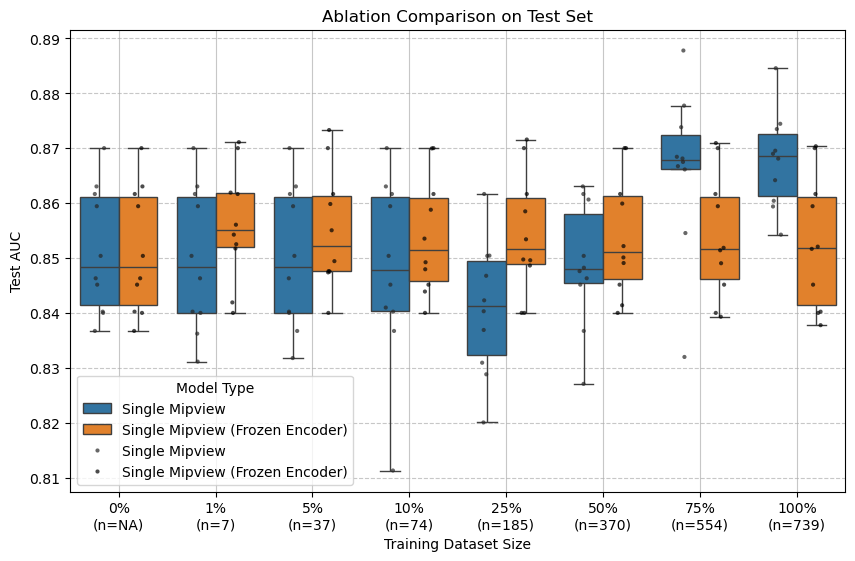

In [10]:
# plot all together as boxplots with strips, but different hues for each type (dual vs single vs single-frozen)
combined_df = pd.DataFrame()
for name, result in ablation_results.items():
    if name == 'Dual Mipview':
        continue
    df = result['ablation_df'].copy()
    df['type'] = name
    combined_df = pd.concat([combined_df, df], ignore_index=True)
combined_df['frac'] = pd.Categorical(combined_df['frac'], categories=sorted(combined_df['frac'].unique()), ordered=True)
plt.figure(figsize=(10, 6))
sns.boxplot(data=combined_df, x='frac', y='auc', hue='type', showfliers=False)
sns.stripplot(data=combined_df, x='frac', y='auc', hue='type', dodge=True, color='black', jitter=0.1, size=3, alpha=0.7)
plt.title('Ablation Comparison on Test Set')
plt.xlabel('Training Dataset Size')
plt.ylabel('Test AUC')
tick_labels = [
    f"{f*100:.0f}%\n(n={ablation_results[next(iter(ablation_results))]['n_train_by_frac'].get(float(f), 'NA')})"
    for f in sorted(combined_df['frac'].unique())
]
plt.xticks(ticks=range(len(tick_labels)), labels=tick_labels)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.grid(axis='x', linestyle='-', alpha=0.7)
plt.legend(title='Model Type', loc='best')
plt.show()

In [ ]:
f1 = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction_using_LARS/val/pred_val_0.csv')
f2 = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/run_lars_on_mars_postfiltering/pred_val_0.csv')